# SMS Spam Detection - TF-IDF vs Sentence-BERT
**ARTI 404 - NLP Project | Section 7MA2 | Group 9**
Instructor: Dr. Mohammed Mosuily

| Name | ID | Parts |
|---|---|---|
| Mohammed Nasser Almarhoon (leader) | 2240005893 | Data cleaning + splits, Method 1 (TF-IDF + LR), Method 1 analysis |
| Ali Zuhair Alsaffar | 2240005706 | Method 2 (SBERT + LR), evaluation, Try it, GitHub/Colab, Method 2 analysis |

**Task:** input is one short English SMS, output is *Spam* or *Not spam*.

**Our question:** which method catches misspelled / obfuscated spam (fr33, w1n, cl4im, txt, msg …) better - TF-IDF + Logistic Regression or Sentence-BERT + Logistic Regression?

Notebook sections: Setup → Data → Method 1 → Method 2 → Results → Challenge subset → Error analysis → Try it → Sources

## 1. Setup

In [ ]:
# only sentence-transformers is missing on colab, the rest is already there
!pip install -q sentence-transformers

In [2]:
import os, re, io, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 42          # same seed everywhere so the splits don't change between runs
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 120)

## 2. Data  *(Mohammed)*
UCI SMS Spam Collection (Almeida et al., 2011). We download the zip from UCI; if UCI is down we use a copy of the same file on GitHub.

In [3]:
UCI_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
BACKUP_URL = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

def load_sms():
    try:
        raw = urllib.request.urlopen(UCI_URL, timeout=30).read()
        with zipfile.ZipFile(io.BytesIO(raw)) as z:
            txt = z.read("SMSSpamCollection").decode("utf-8")
        print("loaded from UCI")
    except Exception as e:
        print("UCI failed (", e, ") -> using github copy")
        txt = urllib.request.urlopen(BACKUP_URL, timeout=30).read().decode("utf-8")
    rows = [line.split("\t", 1) for line in txt.splitlines() if "\t" in line]
    return pd.DataFrame(rows, columns=["label", "text"])

df = load_sms()
print(df.shape)
df.head()

UCI failed ( <urlopen error Tunnel connection failed: 403 Forbidden> ) -> using github copy


(5574, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


label
ham     4827
spam     747
Name: count, dtype: int64


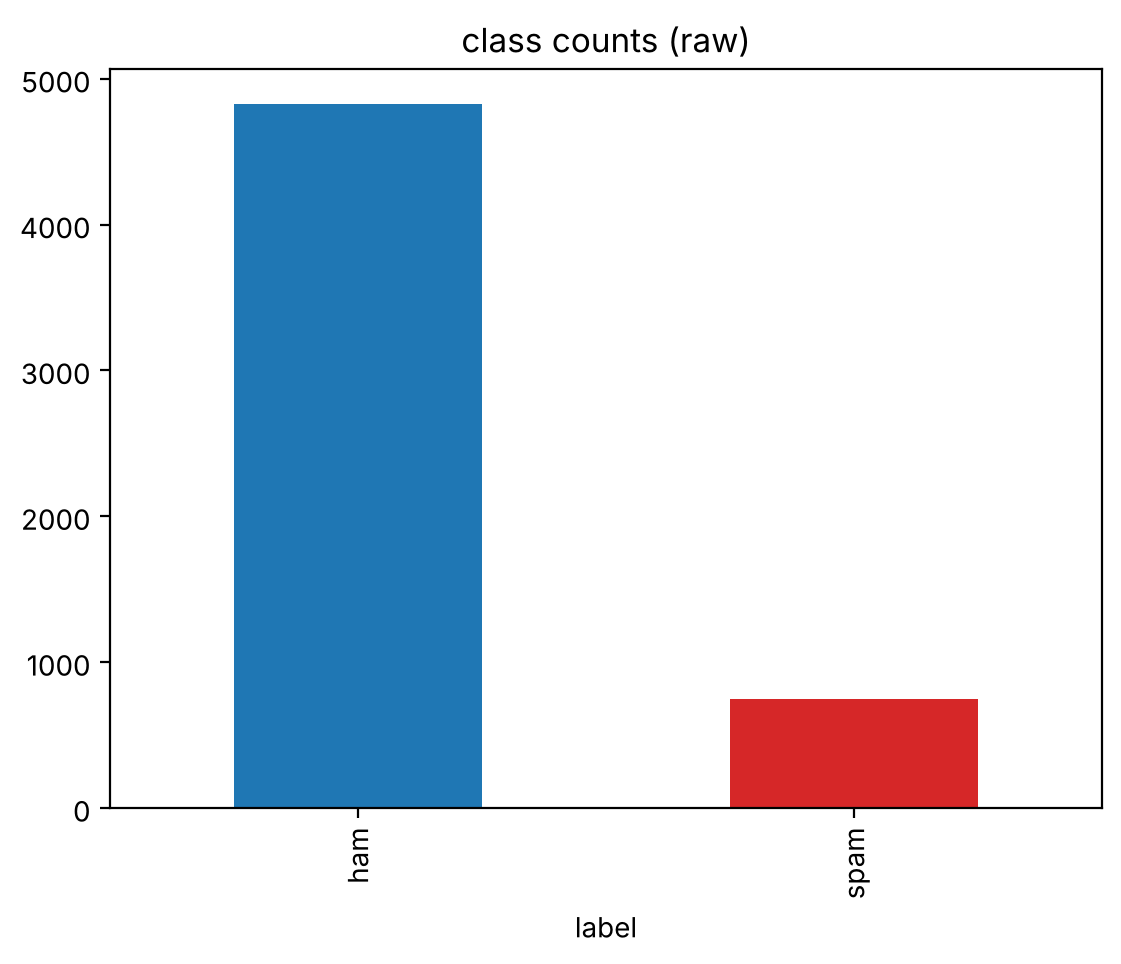

In [4]:
print(df["label"].value_counts())
df["label"].value_counts().plot(kind="bar", title="class counts (raw)", color=["tab:blue", "tab:red"])
plt.show()

### 2.1 Cleaning
As we said in the proposal: drop empty rows and exact duplicates **before** splitting (otherwise the same message can end up in both train and test and the scores look better than they really are).

In [5]:
n0 = len(df)
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"] != ""]
n_empty = n0 - len(df)

n1 = len(df)
df = df.drop_duplicates(subset="text").reset_index(drop=True)
n_dup = n1 - len(df)

df["y"] = (df["label"] == "spam").astype(int)   # ham = 0, spam = 1

print("raw rows        :", n0)
print("empty removed   :", n_empty)
print("dupes removed   :", n_dup)
print("after cleaning  :", len(df))
print(df["label"].value_counts())
print("spam ratio      : %.3f" % df["y"].mean())

raw rows        : 5574
empty removed   : 0
dupes removed   : 414
after cleaning  : 5160
label
ham     4518
spam     642
Name: count, dtype: int64
spam ratio      : 0.124


### 2.2 Train / dev / test split (≈70/15/15, stratified)

In [6]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["y"], random_state=SEED)
dev_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df["y"], random_state=SEED)

for name, d in [("train", train_df), ("dev", dev_df), ("test", test_df)]:
    print(f"{name:5s}: {len(d):5d} msgs | spam = {d['y'].sum():4d} ({d['y'].mean():.3f})")

X_train, y_train = train_df["text"].tolist(), train_df["y"].values
X_dev,   y_dev   = dev_df["text"].tolist(),   dev_df["y"].values
X_test,  y_test  = test_df["text"].tolist(),  test_df["y"].values

train:  3612 msgs | spam =  449 (0.124)
dev  :   774 msgs | spam =   97 (0.125)
test :   774 msgs | spam =   96 (0.124)


## 3. Method 1 - TF-IDF (uni+bigrams) + Logistic Regression  *(Mohammed)*
We lowercase and use word unigrams + bigrams. `class_weight='balanced'` because spam is only ~12% of the data.
We only tune on the **dev** set: `C` (regularization) and `min_df`.

In [7]:
def macro_f1(y, p):
    return f1_score(y, p, average="macro")

m1_results = []
for min_df in [1, 2]:
    for C in [0.1, 1, 10, 100]:
        vec = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=min_df, sublinear_tf=True)
        Xtr = vec.fit_transform(X_train)
        Xdv = vec.transform(X_dev)
        clf = LogisticRegression(C=C, class_weight="balanced", max_iter=2000, random_state=SEED)
        clf.fit(Xtr, y_train)
        p = clf.predict(Xdv)
        m1_results.append({"min_df": min_df, "C": C, "dev_acc": accuracy_score(y_dev, p), "dev_macroF1": macro_f1(y_dev, p)})

m1_tab = pd.DataFrame(m1_results).sort_values("dev_macroF1", ascending=False)
m1_tab

,min_df,C,dev_acc,dev_macroF1
3,1,100.0,0.984496,0.964641
7,2,100.0,0.984496,0.964325
6,2,10.0,0.983204,0.961863
2,1,10.0,0.980620,0.956377
5,2,1.0,0.980620,0.956377
1,1,1.0,0.978036,0.950985
0,1,0.1,0.974160,0.942088
4,2,0.1,0.971576,0.936840


In [8]:
best1 = m1_tab.iloc[0]
print("best on dev ->", dict(best1))

tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=int(best1["min_df"]), sublinear_tf=True)
Xtr_tfidf = tfidf.fit_transform(X_train)
m1 = LogisticRegression(C=float(best1["C"]), class_weight="balanced", max_iter=2000, random_state=SEED)
m1.fit(Xtr_tfidf, y_train)
print("vocab size:", len(tfidf.vocabulary_))

best on dev -> {'min_df': np.float64(1.0), 'C': np.float64(100.0), 'dev_acc': np.float64(0.9844961240310077), 'dev_macroF1': np.float64(0.9646408503251154)}
vocab size: 38364


In [9]:
# quick look at what the model learned - top words for spam and for ham
feat = np.array(tfidf.get_feature_names_out())
w = m1.coef_[0]
print("most spammy :", list(feat[np.argsort(w)[-20:][::-1]]))
print("most hammy  :", list(feat[np.argsort(w)[:20]]))

most spammy : ['call', 'txt', 'text', 'free', 'uk', 'reply', 'claim', 'stop', 'www', 'to', '150p', 'mobile', 'service', '50', 'prize', 'com', '146tf150p', 'won', 'ringtone', 'your']
most hammy  : ['me', 'my', 'your call', 'can', 'that', 'ok', 'gt', 'lt', 'but', 'it', 'lt gt', 'am', 'got', 'how', 'when', 'da', 'he', 'then', 'sorry', 'call me']


## 4. Method 2 - Sentence-BERT embeddings + Logistic Regression  *(Ali)*
`all-MiniLM-L6-v2` from sentence-transformers, **weights frozen** (we only call `encode`, no fine-tuning). Each SMS becomes a 384-dim vector, then the same Logistic Regression classifier is trained on top, tuned on dev the same way.

In [10]:
from sentence_transformers import SentenceTransformer

MODEL_NAME = os.environ.get("SBERT_PATH", "sentence-transformers/all-MiniLM-L6-v2")
sbert = SentenceTransformer(MODEL_NAME, device="cpu")
print("embedding size:", sbert.get_sentence_embedding_dimension())

embedding size: 384


In [11]:
# encoding takes ~1-2 min on colab cpu, faster on gpu
def embed(texts):
    return sbert.encode(texts, batch_size=64, show_progress_bar=False, normalize_embeddings=True)

E_train = embed(X_train)
E_dev   = embed(X_dev)
E_test  = embed(X_test)
print(E_train.shape, E_dev.shape, E_test.shape)

(3612, 384) (774, 384) (774, 384)


In [12]:
m2_results = []
for C in [0.1, 1, 10, 100]:
    clf = LogisticRegression(C=C, class_weight="balanced", max_iter=5000, random_state=SEED)
    clf.fit(E_train, y_train)
    p = clf.predict(E_dev)
    m2_results.append({"C": C, "dev_acc": accuracy_score(y_dev, p), "dev_macroF1": macro_f1(y_dev, p)})

m2_tab = pd.DataFrame(m2_results).sort_values("dev_macroF1", ascending=False)
m2_tab

,C,dev_acc,dev_macroF1
3,100.0,0.984496,0.964950
2,10.0,0.976744,0.949186
1,1.0,0.971576,0.938906
0,0.1,0.963824,0.923483


In [13]:
best2 = m2_tab.iloc[0]
print("best on dev ->", dict(best2))
m2 = LogisticRegression(C=float(best2["C"]), class_weight="balanced", max_iter=5000, random_state=SEED)
m2.fit(E_train, y_train)

best on dev -> {'C': np.float64(100.0), 'dev_acc': np.float64(0.9844961240310077), 'dev_macroF1': np.float64(0.9649498852795556)}


,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",100.0
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

## 5. Results on the test set  *(Ali)*
Test set used **once** here, with the hyperparameters already fixed from dev.

In [14]:
pred1 = m1.predict(tfidf.transform(X_test))
pred2 = m2.predict(E_test)

results = pd.DataFrame([
    {"method": "M1: TF-IDF + LR", "accuracy": accuracy_score(y_test, pred1), "macro_F1": macro_f1(y_test, pred1)},
    {"method": "M2: SBERT + LR",  "accuracy": accuracy_score(y_test, pred2), "macro_F1": macro_f1(y_test, pred2)},
]).round(4)
results

,method,accuracy,macro_F1
0,M1: TF-IDF + LR,0.9845,0.9640
1,M2: SBERT + LR,0.9780,0.9501


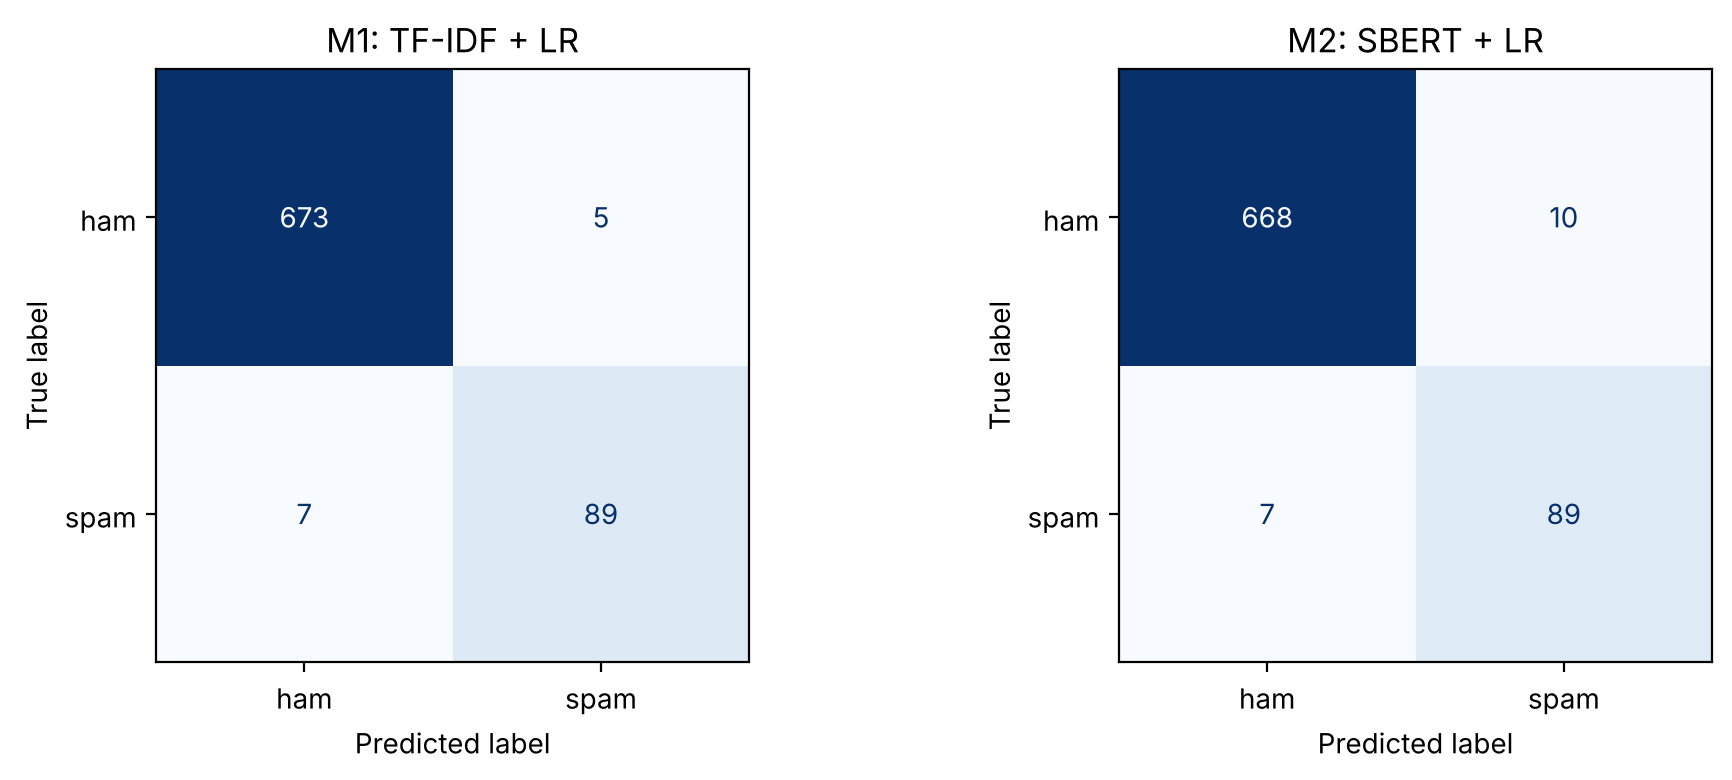

M1
               precision    recall  f1-score   support

         ham      0.990     0.993     0.991       678
        spam      0.947     0.927     0.937        96

    accuracy                          0.984       774
   macro avg      0.968     0.960     0.964       774
weighted avg      0.984     0.984     0.984       774



M2
               precision    recall  f1-score   support

         ham      0.990     0.985     0.987       678
        spam      0.899     0.927     0.913        96

    accuracy                          0.978       774
   macro avg      0.944     0.956     0.950       774
weighted avg      0.978     0.978     0.978       774



In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, p, t in [(ax[0], pred1, "M1: TF-IDF + LR"), (ax[1], pred2, "M2: SBERT + LR")]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["ham", "spam"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(t)
plt.tight_layout(); plt.show()

print("M1\n", classification_report(y_test, pred1, target_names=["ham", "spam"], digits=3))
print("M2\n", classification_report(y_test, pred2, target_names=["ham", "spam"], digits=3))

## 6. Challenge subset - misspelled / obfuscated messages
Fixed rules (written before looking at the results), a message is flagged if it has at least one:
1. **digit inside a word** - a token with both letters and digits (fr33, w1n, 2nite, 4u)
2. **repeated characters** - same letter 3+ times in a row (sooo, freeee)
3. **no-vowel token** of length ≥ 3, letters only (txt, msg, pls, thx)
4. **spam keyword** from a small list (free, win, prize, claim, cash, urgent, award, reply, call now …) - this is for the case where a *ham* message also uses spam-like words

We first count how many test messages get flagged.

In [16]:
KEYWORDS = {"free", "win", "winner", "won", "prize", "claim", "cash", "urgent", "award", "awarded",
            "guaranteed", "bonus", "offer", "reward", "selected", "congratulations", "congrats"}

def tokens(t):
    return re.findall(r"[a-z0-9]+", t.lower())

def has_digit_in_word(t):
    return any(re.search(r"[a-z]", w) and re.search(r"\d", w) for w in tokens(t))

def has_repeat(t):
    return re.search(r"([a-z])\1\1", t.lower()) is not None

def has_novowel(t):
    return any(len(w) >= 3 and w.isalpha() and not re.search(r"[aeiouy]", w) for w in tokens(t))

def has_keyword(t):
    return any(w in KEYWORDS for w in tokens(t))

def flags(t):
    return {"digit_in_word": has_digit_in_word(t), "repeat": has_repeat(t),
            "no_vowel": has_novowel(t), "keyword": has_keyword(t)}

F = pd.DataFrame([flags(t) for t in X_test], index=test_df.index)
test_df = test_df.join(F)
test_df["obfuscated"] = F[["digit_in_word", "repeat", "no_vowel"]].any(axis=1)
test_df["challenge"]  = F.any(axis=1)

print("flag counts on test set:")
print(F.sum())
print("\nchallenge subset size:", test_df["challenge"].sum(), "of", len(test_df))
print(pd.crosstab(test_df["challenge"], test_df["label"]))

flag counts on test set:
digit_in_word     92
repeat            23
no_vowel         121
keyword           63
dtype: int64

challenge subset size: 205 of 774
label      ham  spam
challenge           
False      554    15
True       124    81


In [17]:
# a few flagged examples to check the rules make sense
test_df[test_df["challenge"]][["label", "text", "digit_in_word", "repeat", "no_vowel", "keyword"]].sample(8, random_state=1)

,label,text,digit_in_word,repeat,no_vowel,keyword
4409,spam,"Had your mobile 10 mths? Update to the latest Camera/Video phones for FREE. KEEP UR SAME NUMBER, Get extra free mins...",False,False,True,True
3763,ham,"Forgot you were working today! Wanna chat, but things are ok so drop me a text when you're free / bored etc and i'll...",False,False,False,True
2126,ham,"Goodmorning, today i am late for 2hrs. Because of back pain.",True,False,False,False
366,ham,I'm going for bath will msg you next &lt;#&gt; min..,False,False,True,False
4647,ham,I'm hungry buy smth home...,False,False,True,False
1201,ham,Is ur paper in e morn or aft tmr?,False,False,True,False
4956,spam,"u r subscribed 2 TEXTCOMP 250 wkly comp. 1st wk?s free question follows, subsequent wks charged@150p/msg.2 unsubscri...",True,False,True,True
2315,ham,"Madam,regret disturbance.might receive a reference check from DLF Premarica.kindly be informed.Rgds,Rakhesh,Kerala.",False,False,True,False


The subset is big enough for a comparison (both classes are present), so we keep the definition as it is.
We also report the stricter **obfuscated-only** part (rules 1-3, no keyword rule) since that is closest to our actual question.

In [18]:
test_df["pred1"] = pred1
test_df["pred2"] = pred2

def scores(mask, name):
    d = test_df[mask]
    out = []
    for m, col in [("M1: TF-IDF + LR", "pred1"), ("M2: SBERT + LR", "pred2")]:
        out.append({"subset": name, "n": len(d), "n_spam": int(d["y"].sum()), "method": m,
                    "accuracy": accuracy_score(d["y"], d[col]), "macro_F1": macro_f1(d["y"], d[col]),
                    "errors": int((d["y"] != d[col]).sum())})
    return out

rows = []
rows += scores(test_df.index == test_df.index, "full test")
rows += scores(test_df["challenge"], "challenge (all 4 rules)")
rows += scores(test_df["obfuscated"], "obfuscated only (rules 1-3)")
rows += scores(~test_df["challenge"], "not flagged")
sub_res = pd.DataFrame(rows).round(4)
sub_res

,subset,n,n_spam,method,accuracy,macro_F1,errors
0,full test,774,96,M1: TF-IDF + LR,0.9845,0.9640,12
1,full test,774,96,M2: SBERT + LR,0.9780,0.9501,17
2,challenge (all 4 rules),205,81,M1: TF-IDF + LR,0.9561,0.9538,9
3,challenge (all 4 rules),205,81,M2: SBERT + LR,0.9707,0.9694,6
4,obfuscated only (rules 1-3),184,73,M1: TF-IDF + LR,0.9620,0.9598,7
5,obfuscated only (rules 1-3),184,73,M2: SBERT + LR,0.9837,0.9829,3
6,not flagged,569,15,M1: TF-IDF + LR,0.9947,0.9503,3
7,not flagged,569,15,M2: SBERT + LR,0.9807,0.8284,11


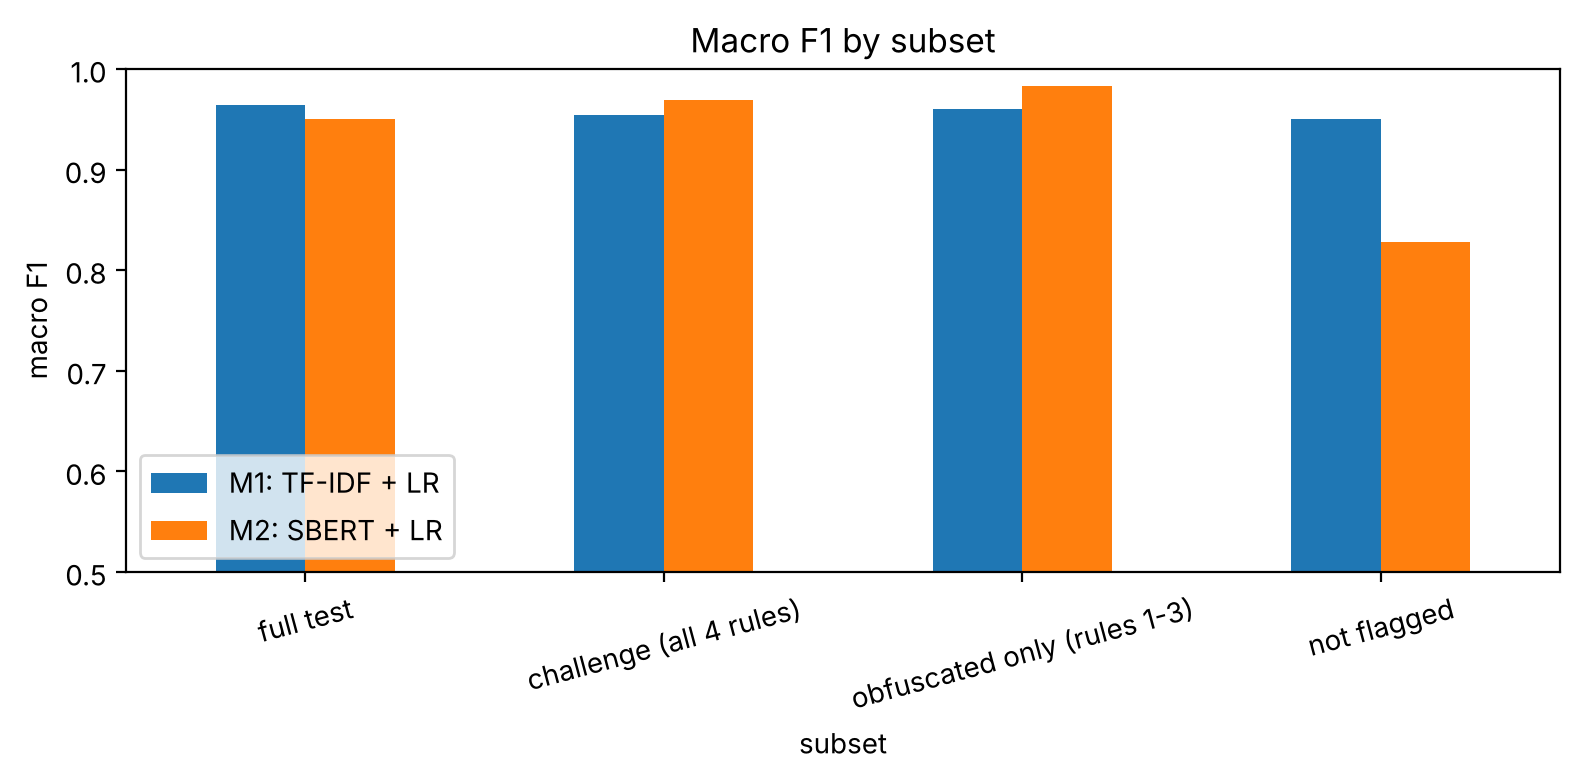

In [19]:
piv = sub_res.pivot(index="subset", columns="method", values="macro_F1").loc[
    ["full test", "challenge (all 4 rules)", "obfuscated only (rules 1-3)", "not flagged"]]
piv.plot(kind="bar", figsize=(8, 4), ylim=(0.5, 1.0), rot=15, title="Macro F1 by subset")
plt.ylabel("macro F1"); plt.legend(loc="lower left"); plt.tight_layout(); plt.show()

In [20]:
# spam recall inside the challenge subset = how many obfuscated spams each one actually caught
ch = test_df[test_df["challenge"] & (test_df["y"] == 1)]
print("spam msgs in challenge subset:", len(ch))
print("M1 caught:", int(ch["pred1"].sum()), " | M2 caught:", int(ch["pred2"].sum()))

hc = test_df[test_df["keyword"] & (test_df["y"] == 0)]
print("\nham msgs that contain a spam keyword:", len(hc))
print("M1 false alarms:", int(hc["pred1"].sum()), " | M2 false alarms:", int(hc["pred2"].sum()))

spam msgs in challenge subset: 81
M1 caught: 75  | M2 caught: 78

ham msgs that contain a spam keyword: 17
M1 false alarms: 3  | M2 false alarms: 3


### 6.1 Extra check - we obfuscate the test spam ourselves
The natural subset is small, so as an extra test we took the **spam messages of the test set** and replaced letters the way spammers do (e->3, i->1, o->0, a->4, s->5) with probability `p`. Ham is not touched. Models are **not retrained**. We measure spam recall (how many are still caught).

In [21]:
LEET = {"e": "3", "i": "1", "o": "0", "a": "4", "s": "5"}
def leetify(t, p, rng):
    return "".join(LEET[c.lower()] if c.lower() in LEET and rng.random() < p else c for c in t)

spam_test = test_df[test_df["y"] == 1]["text"].tolist()
rows = []
for p in [0.0, 0.1, 0.25, 0.5]:
    rng = np.random.default_rng(SEED)
    obf = [leetify(t, p, rng) for t in spam_test]
    r1 = m1.predict(tfidf.transform(obf)).mean()
    r2 = m2.predict(embed(obf)).mean()
    rows.append({"p_replace": p, "M1 spam recall": round(r1, 3), "M2 spam recall": round(r2, 3)})
leet_res = pd.DataFrame(rows)
print("example (p=0.25):", leetify(spam_test[0], 0.25, np.random.default_rng(SEED)))
leet_res

example (p=0.25): WINNER!! As 4 valued netw0rk customer you have b3en 5elected to receiv3a £900 pr1z3 reward! To claim call 09061701461. Cl41m cod3 KL341. Valid 12 hours only.


,p_replace,M1 spam recall,M2 spam recall
0,0.00,0.927,0.927
1,0.10,0.927,0.938
2,0.25,0.906,0.938
3,0.50,0.823,0.969


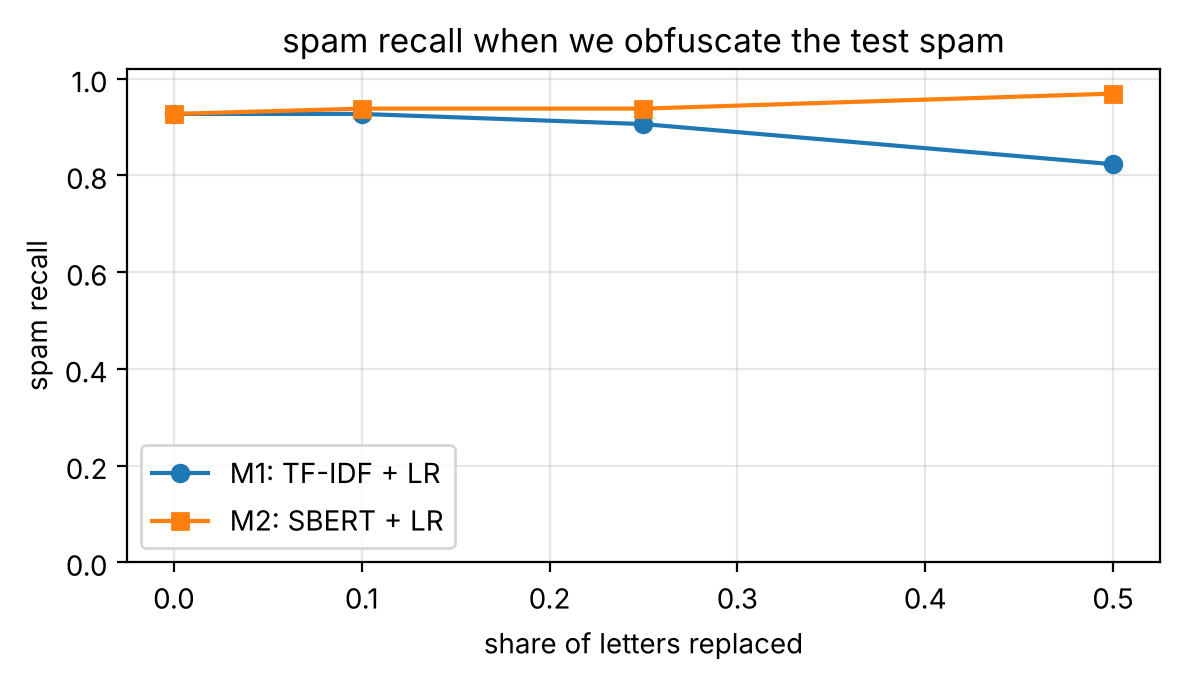

In [22]:
plt.figure(figsize=(6, 3.5))
plt.plot(leet_res["p_replace"], leet_res["M1 spam recall"], "o-", label="M1: TF-IDF + LR")
plt.plot(leet_res["p_replace"], leet_res["M2 spam recall"], "s-", label="M2: SBERT + LR")
plt.xlabel("share of letters replaced"); plt.ylabel("spam recall"); plt.ylim(0, 1.02)
plt.title("spam recall when we obfuscate the test spam"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 7. Error analysis
All wrong predictions from each method on the test set.

In [23]:
err1 = test_df[test_df["pred1"] != test_df["y"]][["label", "text", "pred2", "challenge"]].assign(
    M1_pred=lambda d: np.where(test_df.loc[d.index, "pred1"] == 1, "spam", "ham"),
    M2_pred=lambda d: np.where(d["pred2"] == 1, "spam", "ham")).drop(columns="pred2")
print("M1 errors:", len(err1))
err1

M1 errors: 12


,label,text,challenge,M1_pred,M2_pred
1029,ham,I'm at work. Please call,False,spam,ham
152,ham,Ok... Ur typical reply...,False,spam,ham
3327,spam,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & S...",True,ham,spam
1230,spam,Can U get 2 phone NOW? I wanna chat 2 set up meet Call me NOW on 09096102316 U can cum here 2moro Luv JANE xx Calls£...,True,ham,spam
3173,spam,Sorry I missed your call let's talk when you have the time. I'm on 07090201529,False,ham,ham
2967,spam,"LookAtMe!: Thanks for your purchase of a video clip from LookAtMe!, you've been charged 35p. Think you can do better...",True,ham,spam
2196,ham,Dont you have message offer,True,spam,spam
5130,spam,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A SHIT....,True,ham,spam
2326,spam,Guess who am I?This is the first time I created a web page WWW.ASJESUS.COM read all I wrote. I'm waiting for your op...,True,ham,ham
1456,ham,Total video converter free download type this in google search:),True,spam,ham


In [24]:
err2 = test_df[test_df["pred2"] != test_df["y"]][["label", "text", "pred1", "challenge"]].assign(
    M1_pred=lambda d: np.where(d["pred1"] == 1, "spam", "ham"),
    M2_pred=lambda d: np.where(test_df.loc[d.index, "pred2"] == 1, "spam", "ham")).drop(columns="pred1")
print("M2 errors:", len(err2))
err2

M2 errors: 17


,label,text,challenge,M1_pred,M2_pred
3267,ham,i am seeking a lady in the street and a freak in the sheets. Is that you?,False,ham,spam
612,ham,MAKE SURE ALEX KNOWS HIS BIRTHDAY IS OVER IN FIFTEEN MINUTES AS FAR AS YOU'RE CONCERNED,False,ham,spam
1926,spam,TheMob>Yo yo yo-Here comes a new selection of hot downloads for our members to get for FREE! Just click & open the n...,True,spam,ham
3383,ham,I've sent my wife your text. After we buy them she'll tell you what to do. So just relax. We should go get them this...,False,ham,spam
3655,ham,Unlimited texts. Limited minutes.,False,ham,spam
3606,ham,Early bird! Any purchases yet?,False,ham,spam
4988,ham,Its sunny in california. The weather's just cool,False,ham,spam
3811,ham,"Aight I've been set free, think you could text me blake's address? It occurs to me I'm not quite as sure what I'm do...",True,ham,spam
1828,spam,"FreeMsg Hey U, i just got 1 of these video/pic fones, reply WILD to this txt & ill send U my pics, hurry up Im so bo...",True,spam,ham
3173,spam,Sorry I missed your call let's talk when you have the time. I'm on 07090201529,False,ham,ham


In [25]:
both = set(err1.index) & set(err2.index)
print("wrong in both:", len(both), "| only M1:", len(set(err1.index) - both), "| only M2:", len(set(err2.index) - both))

wrong in both: 4 | only M1: 8 | only M2: 13


### 7.1 Method 1 errors (TF-IDF + LR) - *Mohammed*
M1 made 12 mistakes on the test set (5 false alarms, 7 missed spam).

1. **"I'm at work. Please call"** (ham → spam). Very short message and "call" is the #1 spam word for our model (see the top words in section 3). With only 4-5 words nothing else pulls it back to ham. SBERT got this one right.
2. **"Can U get 2 phone NOW? I wanna chat 2 set up meet ... 2moro Luv JANE xx"** and the similar "CLAIRE here am havin borin time ... 2nite?" (spam → ham). These are chat-line spams written exactly like a friend texting (U, 2, 2moro, 2nite, xx). For TF-IDF these tokens appear a lot in ham too, so the score ends up on the ham side. SBERT caught both. This is the kind of challenge case we were asking about.
3. **"ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS ... L8ER GOT MEGA BILL"** (spam → ham). Spam that pretends to be a complaint from a normal person, full of misspellings (SED, GIV, L8ER). Most of these spellings are rare, so they have little or no weight in our vocabulary.
4. **"Total video converter free download type this in google search:)"** (ham → spam). The word "free" + "download" is enough for M1 to call it spam even though it is just a friend giving a tip.
5. **"Sorry I missed your call let's talk when you have the time. I'm on 07090201529"** (spam → ham, both methods wrong). The text itself is completely normal; the only spam signal is the premium 070 number. Every phone number is a different token for TF-IDF so it can't learn from it, and SBERT only sees the meaning, which is harmless.

### 7.2 Method 2 errors (SBERT + LR) - *Ali*
M2 made 17 mistakes (10 false alarms, 7 missed spam). Most of its extra mistakes are false alarms on normal ham that are **not** in the challenge subset.

1. **"Unlimited texts. Limited minutes."** and **"Early bird! Any purchases yet?"** (ham → spam). By meaning they talk about phone plans and buying things, which is close to promo spam in embedding space, even though nothing here is actually spam. TF-IDF got both right because the exact words are not strong spam words.
2. **"Its sunny in california. The weather's just cool"** and **"Send me the new number"** (ham → spam). Short and neutral messages. With a 384-dim sentence vector there is not much signal in short texts and the classifier sometimes puts them on the wrong side. We think this is the main weakness of M2.
3. **"TheMob>Yo yo yo-Here comes a new selection of hot downloads for our members to get for FREE!"** (spam → ham). The slang tone ("Yo yo yo") makes it look like casual chat to SBERT. M1 caught it from words like "free", "members", "click".
4. **"3. You have received your mobile content. Enjoy"** and **"Adult 18 Content Your video will be with you shortly"** (spam → ham). These look like normal service notices by meaning. M1 caught them because "content" and "mobile" have high spam weight in this dataset.
5. **"Dont you have message offer"** and **"I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS..."** (ham → spam, both wrong). The second one honestly reads like spam to us too, we think it is close to label noise in the dataset.

**Overlap:** only 4 messages are wrong in both, 8 only in M1 and 13 only in M2, so the two methods fail on quite different messages.

## 8. Try it  *(Ali)*
Classifies a new SMS with the trained models - no retraining. Empty input is handled.

In [26]:
def classify(msg, method="both"):
    msg = (msg or "").strip()
    if not msg:
        return "Please type a message (input was empty)."
    p1 = m1.predict_proba(tfidf.transform([msg]))[0, 1]
    p2 = m2.predict_proba(embed([msg]))[0, 1]
    lab = lambda p: "Spam" if p >= 0.5 else "Not spam"
    if method == "tfidf": return f"TF-IDF+LR: {lab(p1)} (p_spam={p1:.2f})"
    if method == "sbert": return f"SBERT+LR: {lab(p2)} (p_spam={p2:.2f})"
    return f"TF-IDF+LR: {lab(p1)} (p_spam={p1:.2f}) | SBERT+LR: {lab(p2)} (p_spam={p2:.2f})"

print(classify("You won a cash prize. Pay a fee now to claim it"))
print(classify(""))

TF-IDF+LR: Spam (p_spam=1.00) | SBERT+LR: Spam (p_spam=0.99)
Please type a message (input was empty).


### Our own labelled examples
Two messages each, written by us (not from the dataset), with the label we expect.

In [27]:
own = pd.DataFrame([
    # Mohammed
    ("Mohammed", "Congratz!! u hav been selected 4 a FR33 iPh0ne, cl4im now @ www.get-it-fast.co", "spam"),
    ("Mohammed", "bro r u free tmrw? need help moving the table to my place", "ham"),
    # Ali
    ("Ali", "URGENT ur acc0unt is l0cked. txt VERIFY to 80085 to unlock b4 midnight", "spam"),
    ("Ali", "Dr said the quiz is free to retake next week, dont stress", "ham"),
], columns=["by", "text", "expected"])

own["M1"] = np.where(m1.predict(tfidf.transform(own["text"])) == 1, "spam", "ham")
own["M2"] = np.where(m2.predict(embed(own["text"].tolist())) == 1, "spam", "ham")
own

,by,text,expected,M1,M2
0,Mohammed,"Congratz!! u hav been selected 4 a FR33 iPh0ne, cl4im now @ www.get-it-fast.co",spam,spam,spam
1,Mohammed,bro r u free tmrw? need help moving the table to my place,ham,ham,ham
2,Ali,URGENT ur acc0unt is l0cked. txt VERIFY to 80085 to unlock b4 midnight,spam,spam,spam
3,Ali,"Dr said the quiz is free to retake next week, dont stress",ham,spam,ham


In [ ]:
# interactive box (colab) - type a message and press enter, empty line to stop
try:
    while True:
        s = input("SMS> ")
        if s.strip() == "":
            print(classify(s)); break
        print(classify(s))
except (EOFError, KeyboardInterrupt):
    pass

## 9. Conclusion

| | M1: TF-IDF + LR | M2: SBERT + LR |
|---|---|---|
| Full test - Accuracy | **0.9845** | 0.9780 |
| Full test - Macro F1 | **0.9640** | 0.9501 |
| Challenge subset (n=205) - Macro F1 | 0.9538 | **0.9694** |
| Obfuscated only (n=184) - Macro F1 | 0.9598 | **0.9829** |
| Challenge spam caught (of 81) | 75 | **78** |
| Spam recall, 50% of letters obfuscated by us | 0.823 | **0.969** |

**Answer to our question:** on the misspelled / obfuscated messages, **Sentence-BERT + LR was more reliable**. It made fewer errors on the challenge subset (6 vs 9) and when we obfuscated the test spam ourselves its recall stayed high while TF-IDF dropped from 0.93 to 0.82. The reason makes sense: a word like "cl4im" is a new, unknown token for TF-IDF (so it adds nothing), but the SBERT tokenizer splits it into pieces and the sentence still "means" the same thing.

**But** on the full test set TF-IDF is a bit better, because SBERT gives more false alarms on short, normal messages (11 errors on the non-flagged part vs 3 for TF-IDF). So which one is "better" depends on the messages: TF-IDF for normal SMS traffic, SBERT if spammers start hiding words.

**Limitations**
- The differences on the challenge subset are only a few messages (6 vs 9 errors), so with a different split the gap could be smaller. We only used one split (seed 42).
- Our heuristic rules also flag a lot of normal ham (txt, msg, pls are common in casual texting), so the challenge subset is not 100% obfuscated spam.
- In the extra leetspeak test we only changed spam, we did not check if obfuscated *ham* also gets flagged as spam by SBERT, so part of its higher recall could be because "weird looking" text in general looks spammy to it.
- A possible next step would be character n-grams for TF-IDF, which should handle misspellings much better than word n-grams.

## Sources
[1] T. A. Almeida, J. M. G. Hidalgo, and A. Yamakami, "Contributions to the study of SMS spam filtering: new collection and results," *Proc. 11th ACM Symposium on Document Engineering (DocEng)*, 2011, pp. 259-262. Dataset: https://archive.ics.uci.edu/dataset/228/sms+spam+collection

[2] N. Reimers and I. Gurevych, "Sentence-BERT: Sentence embeddings using Siamese BERT-networks," *Proc. EMNLP-IJCNLP*, 2019, pp. 3982-3992. Model: https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2

Libraries: scikit-learn, sentence-transformers, pandas, numpy, matplotlib.